# 15 · Combined focal-leaf test report

One test set from the two second-round hydrangea test projects, scored **only on the labelled focal leaf**:

| Source | Photos | How the labels were made |
|---|---|---|
| `prelabelled` | `powdery-mildew-ds2-focal-test-23n1f` | model pre-labels (leaf outline redrawn by SAM 2.1), then corrected by hand: **optimistic** for spots and mildew, because many labels started as the model's own drafts |
| `scratch` | `powdery-mildew-ds2-scratch-test` | drawn **from scratch**, no model help: the independent reference |

Every photo keeps its source tag. Numbers are given for **all photos together** and for **each source**, so the effect of the pre-labels stays visible.

**How the model is run (exactly like the app):** the backend's own ONNX inference (`backend/app/inference.py`, including the leaf-crop fix), photo capped at 1280 px on the long side, model input 1024, per-class thresholds `leaf 0.20 · leaf spot 0.25 · mildew 0.30`. The model sees the **full photo**; only the scoring is restricted:

| Class | What is scored |
|---|---|
| `leaf` | the app's main leaf (the largest predicted leaf, holes filled) against the labelled focal leaf |
| `leaf_spot`, `powdery_mildew` | predicted patches lying at least half inside the labelled focal leaf, against all labelled patches on it |

**Metrics:** precision, recall and F1 per class (a prediction matches a label at mask IoU ≥ 0.5); mask AP50 and AP50-95 (COCO); pixel precision, recall, F1 and IoU inside the focal leaf; coverage % of the leaf (error, bias, agreement, severity band); and Ultralytics `val` on photos greyed out everywhere except the focal leaf. 95 % confidence ranges are bootstrapped over photos.

In [1]:
import collections
import contextlib
import csv
import io
import json
import os
import re
import shutil
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from dotenv import load_dotenv
from IPython.display import Image as IPImage, display
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from PIL import Image, ImageOps
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT.parent / "backend"))
from app.inference import SegmentationModel  # the app's own ONNX inference

from eval_utils import CLASSES, DISEASES, coverage_primary_leaf, ensure_dataset, fill_holes, lins_ccc, paint_class_map, severity

load_dotenv(ROOT / ".env")  # ROBOFLOW_API_KEY lives here (gitignored); never paste the key into a notebook
SOURCES = [
    {"key": "prelabelled", "name": "pre-labelled", "project": "powdery-mildew-ds2-focal-test-23n1f", "version": 1},
    {"key": "scratch", "name": "from scratch", "project": "powdery-mildew-ds2-scratch-test", "version": 1},
]
ONNX = ROOT.parent / "backend" / "models" / "leaf_disease_seg.onnx"  # export of runs/yolo26x-seg_data-v2/weights/best.pt
CHECKPOINT = ROOT / "runs" / "yolo26x-seg_data-v2" / "weights" / "best.pt"  # Ultralytics val only
THRESH = {"leaf": 0.20, "leaf_spot": 0.25, "powdery_mildew": 0.30}  # backend/app/config.py
APP_SIDE, APP_IMGSZ = 1280, 1024  # photo long side cap (backend) / model input (exported ONNX)
MATCH_IOU = 0.5
GREY = (114, 114, 114)
N_BOOT, SEED = 1000, 0
OUT = ROOT / "results" / "focal_test_combined"
OUT.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4, fixed order
CLASS_COLOR = {"leaf": SERIES[0], "leaf_spot": SERIES[1], "powdery_mildew": SERIES[2]}
METRIC_COLOR = {"precision": SERIES[0], "recall": SERIES[1], "f1": SERIES[2], "iou": SERIES[3]}
SRC_COLOR = {"prelabelled": MUTED, "scratch": "#7b5fc9"}  # grey = less independent labels; violet = from scratch
NICE = {"leaf": "leaf", "leaf_spot": "leaf spot", "powdery_mildew": "mildew"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "savefig.dpi": 150, "savefig.bbox": "tight",
})
MAP_COLORS = ListedColormap(["#f0efec", "#b7d3f6", CLASS_COLOR["leaf_spot"], CLASS_COLOR["powdery_mildew"]])
BLUES = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
print("model:", ONNX.name, "| thresholds:", THRESH, "| results ->", OUT.relative_to(ROOT))

model: leaf_disease_seg.onnx | thresholds: {'leaf': 0.2, 'leaf_spot': 0.25, 'powdery_mildew': 0.3} | results -> results\focal_test_combined


c:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · Data

In [2]:
DS, ITEMS = {}, []
for src in SOURCES:
    coco_dir, yolo_yaml = ensure_dataset(ROOT, src["project"], src["version"], os.environ["ROBOFLOW_API_KEY"], os.environ["ROBOFLOW_WORKSPACE"])
    gt = COCO(str(coco_dir / "test" / "_annotations.coco.json"))
    cat = {c["id"]: c["name"] for c in gt.loadCats(gt.getCatIds())}
    DS[src["key"]] = {"gt": gt, "cat": cat, "coco_dir": coco_dir, "yolo_dir": Path(yolo_yaml).parent, "yaml": yolo_yaml}
    leaves = collections.Counter(a["image_id"] for a in gt.loadAnns(gt.getAnnIds()) if cat[a["category_id"]] == "leaf")
    for img in sorted(gt.loadImgs(gt.getImgIds()), key=lambda i: i["file_name"]):
        stem = re.match(r"(\d{8}_\d{9}_iOS)", img["file_name"]).group(1)
        if leaves[img["id"]] == 0:
            print(f"skipped, no leaf label: {src['key']} {stem}")
            continue
        ITEMS.append({"source": src["key"], "stem": stem, "img": img, "file": img["file_name"]})
stems = [i["stem"] for i in ITEMS]
assert len(stems) == len(set(stems)), "the same photo is in both sets"

n_src = collections.Counter(i["source"] for i in ITEMS)
SRC_LABEL = {s["key"]: f"{s['name']} (n={n_src[s['key']]})" for s in SOURCES}
inst = collections.defaultdict(collections.Counter)
for it in ITEMS:
    ds = DS[it["source"]]
    for a in ds["gt"].loadAnns(ds["gt"].getAnnIds(imgIds=it["img"]["id"])):
        inst[it["source"]][ds["cat"][a["category_id"]]] += 1
print(f"\n{'source':<24}{'photos':>8}{'leaf':>7}{'leaf spot':>11}{'mildew':>9}")
for s in SOURCES:
    c = inst[s["key"]]
    print(f"{SRC_LABEL[s['key']]:<24}{n_src[s['key']]:>8}{c['leaf']:>7}{c['leaf_spot']:>11}{c['powdery_mildew']:>9}")
tot = sum(inst.values(), collections.Counter())
print(f"{'all':<24}{len(ITEMS):>8}{tot['leaf']:>7}{tot['leaf_spot']:>11}{tot['powdery_mildew']:>9}")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
skipped, no leaf label: prelabelled 20261001_183427153_iOS
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!

source                    photos   leaf  leaf spot   mildew
pre-labelled (n=49)           49     50        805      941
from scratch (n=8)             8      8         94      118
all                           57     58        899     1059


In [3]:
def app_image(path):
    # Same as backend/app/routes/scans.py load_image: EXIF orientation, long side capped at 1280.
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    im.thumbnail((APP_SIDE, APP_SIDE), Image.Resampling.LANCZOS)
    return im


def gt_at(ds, img, size):
    # Labelled masks rasterised directly at the working size.
    w, h = size
    sx, sy = w / img["width"], h / img["height"]
    out = {c: [] for c in CLASSES[1:]}
    for a in ds["gt"].loadAnns(ds["gt"].getAnnIds(imgIds=img["id"])):
        name = ds["cat"][a["category_id"]]
        polys = [[v * (sx if k % 2 == 0 else sy) for k, v in enumerate(p)] for p in a["segmentation"] if len(p) >= 6]
        if name in out and polys:
            out[name].append(mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(polys, h, w))).astype(bool))
    return out


def focal_leaf(g):
    # Focal leaf = all labelled leaf shapes + the lesions on them, holes filled (lesions count as leaf area, as in the app).
    return fill_holes(np.logical_or.reduce(g["leaf"] + g["leaf_spot"] + g["powdery_mildew"])) if g["leaf"] else None


def rle(m):
    r = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
    r["counts"] = r["counts"].decode()
    return r


def sev(pct):
    return "none" if pct <= 0 else severity(pct)

## 2 · Run the model on every photo

For each photo: predict on the full photo with the app's ONNX path, keep the **main leaf** (largest predicted leaf), keep the **disease patches that lie on the labelled leaf**, and record the labelled and predicted coverage. Neighbouring leaves are ignored.

In [4]:
model = SegmentationModel(str(ONNX), None, 300, "v2")
CAT_ID = {"leaf": 1, "leaf_spot": 2, "powdery_mildew": 3}
gt_coco = {"images": [], "annotations": [], "categories": [{"id": i, "name": n} for n, i in CAT_ID.items()]}
dets, per_image = [], []
for k, it in enumerate(ITEMS, 1):
    ds, img = DS[it["source"]], it["img"]
    im = app_image(ds["coco_dir"] / "test" / it["file"])
    g = gt_at(ds, img, im.size)
    leaf_gt = focal_leaf(g)
    h, w = leaf_gt.shape
    preds = [(p["class_name"], p["confidence"], p["mask"]) for p in model.predict(np.asarray(im), min(THRESH.values()))
             if p["confidence"] >= THRESH.get(p["class_name"], 1.1)]
    leaves = sorted(((s, fill_holes(m)) for n, s, m in preds if n == "leaf"), key=lambda x: -int(x[1].sum()))
    primary_conf, primary = leaves[0] if leaves else (0.0, np.zeros((h, w), bool))
    lesions = [(n, s, m) for n, s, m in preds if n != "leaf" and (m & leaf_gt).sum() >= 0.5 * m.sum()]

    gt_coco["images"].append({"id": k, "file_name": it["file"], "width": w, "height": h})
    gt_inst = {"leaf": [rle(leaf_gt)], **{d: [rle(m) for m in g[d]] for d in DISEASES}}
    for c, rs in gt_inst.items():
        for x in rs:
            gt_coco["annotations"].append({"id": len(gt_coco["annotations"]) + 1, "image_id": k, "category_id": CAT_ID[c],
                                           "segmentation": x, "iscrowd": 0, "area": float(mask_utils.area(x)),
                                           "bbox": list(mask_utils.toBbox(x))})
    dt_inst = {"leaf": [(primary_conf, rle(primary))] if leaves else [], **{d: [(s, rle(m)) for n, s, m in lesions if n == d] for d in DISEASES}}
    for c, ds_ in dt_inst.items():
        dets += [{"image_id": k, "category_id": CAT_ID[c], "segmentation": x, "score": s} for s, x in ds_]

    # pixel maps: the leaf over the whole photo, the diseases inside the labelled leaf
    gt_map = paint_class_map(sum((g[c] for c in CLASSES[1:]), []), sum(([c] * len(g[c]) for c in CLASSES[1:]), []), (h, w))
    gt_map[leaf_gt & (gt_map == 0)] = CLASSES.index("leaf")  # filled holes count as leaf
    pred_map = paint_class_map([primary] + [m for _, _, m in lesions], ["leaf"] + [n for n, _, _ in lesions], (h, w))
    pix = {"leaf": {"tp": int((primary & leaf_gt).sum()), "fp": int((primary & ~leaf_gt).sum()), "fn": int((~primary & leaf_gt).sum())}}
    for d in DISEASES:
        c = CLASSES.index(d)
        p_, t_ = (pred_map == c) & leaf_gt, (gt_map == c) & leaf_gt
        pix[d] = {"tp": int((p_ & t_).sum()), "fp": int((p_ & ~t_).sum()), "fn": int((~p_ & t_).sum())}
    area = float(leaf_gt.sum())
    per_image.append({
        "id": k, "source": it["source"], "stem": it["stem"], "file": it["file"], "gt_inst": gt_inst, "dt_inst": dt_inst, "pix": pix,
        "gt_area_frac": {d: [100 * float(mask_utils.area(x)) / area for x in gt_inst[d]] for d in DISEASES},
        "cov_gt": {d: 100 * ((gt_map == CLASSES.index(d)) & leaf_gt).sum() / area for d in DISEASES},
        "cov_pred": {d: 100 * ((pred_map == CLASSES.index(d)) & leaf_gt).sum() / area for d in DISEASES},
        "cov_app": coverage_primary_leaf([m for _, _, m in preds], [n for n, _, _ in preds]) or {d: 0.0 for d in DISEASES},
        "leaf_iou": float((primary & leaf_gt).sum() / max((primary | leaf_gt).sum(), 1)),
        "other_leaves_ignored": max(len(leaves) - 1, 0), "maps": (gt_map, pred_map, leaf_gt), "im": im})
    if k % 10 == 0 or k == len(ITEMS):
        print(f"{k}/{len(ITEMS)} photos", flush=True)
print(f"scored {len(per_image)} photos | neighbouring-leaf predictions ignored: {sum(p['other_leaves_ignored'] for p in per_image)}")

10/57 photos
20/57 photos
30/57 photos
40/57 photos
50/57 photos
57/57 photos
scored 57 photos | neighbouring-leaf predictions ignored: 961


## 3 · Numbers

Matching: each labelled patch is matched at most once, by predicted patch confidence, at mask IoU ≥ 0.5. Bootstrap: 1,000 resamples of the photos (each group resampled within itself).

In [5]:
def match_detail(gt_rles, dt):
    # Greedy one-to-one matching by score -> (labelled patch found?, predicted patch correct?)
    hit, dhit = [False] * len(gt_rles), [False] * len(dt)
    if not gt_rles or not dt:
        return hit, dhit
    order = sorted(range(len(dt)), key=lambda i: -dt[i][0])
    ious = np.asarray(mask_utils.iou([dt[i][1] for i in order], gt_rles, [0] * len(gt_rles))).reshape(len(order), len(gt_rles))
    used = set()
    for r, i in enumerate(order):
        free = [j for j in range(len(gt_rles)) if j not in used]
        if free:
            j = max(free, key=lambda j: ious[r, j])
            if ious[r, j] >= MATCH_IOU:
                used.add(j); hit[j] = True; dhit[i] = True
    return hit, dhit


for p in per_image:
    p["gt_hit"], p["inst"] = {}, {}
    for c in CLASSES[1:]:
        hit, dhit = match_detail(p["gt_inst"][c], p["dt_inst"][c])
        p["gt_hit"][c] = hit
        tp = sum(hit)
        p["inst"][c] = (tp, len(dhit) - tp, len(hit) - tp)


def prf(tp, fp, fn):
    pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"precision": pr, "recall": rc, "f1": 2 * pr * rc / max(pr + rc, 1e-9), "iou": tp / max(tp + fp + fn, 1)}


def scores(rows):
    out = {}
    for c in CLASSES[1:]:
        tp, fp, fn = (sum(r["inst"][c][i] for r in rows) for i in range(3))
        for k, v in prf(tp, fp, fn).items():
            if k != "iou":
                out[f"instance.{c}.{k}"] = v
        ptp, pfp, pfn = (sum(r["pix"][c][k] for r in rows) for k in ("tp", "fp", "fn"))
        for k, v in prf(ptp, pfp, pfn).items():
            out[f"pixel.{c}.{k}"] = v
    for d in DISEASES:
        g = np.array([r["cov_gt"][d] for r in rows]); p = np.array([r["cov_pred"][d] for r in rows])
        a = np.array([r["cov_app"][d] for r in rows])
        pos = g > 0
        tp, fp, fn = int(((p > 0) & pos).sum()), int(((p > 0) & ~pos).sum()), int(((p == 0) & pos).sum())
        out[f"coverage.{d}.mae"], out[f"coverage.{d}.bias"] = float(np.abs(p - g).mean()), float((p - g).mean())
        out[f"coverage.{d}.ccc"] = lins_ccc(g, p)
        out[f"coverage.{d}.severity_acc"] = float(np.mean([sev(x) == sev(y) for x, y in zip(g, p)]))
        out[f"coverage.{d}.presence_f1"] = 2 * tp / max(2 * tp + fp + fn, 1)
        out[f"coverage_app_rule.{d}.mae"] = float(np.abs(a - g).mean())
    out["primary_leaf_correct"] = float(np.mean([r["leaf_iou"] >= 0.5 for r in rows]))
    return out


GROUPS = {"all": per_image, **{s["key"]: [p for p in per_image if p["source"] == s["key"]] for s in SOURCES}}
GROUP_LABEL = {"all": f"all photos (n={len(per_image)})", **SRC_LABEL}
RESULTS = {}
for gname, rows in GROUPS.items():
    point = scores(rows)
    rng = np.random.default_rng(SEED)
    boots = [scores([rows[i] for i in rng.integers(0, len(rows), len(rows))]) for _ in range(N_BOOT)]
    RESULTS[gname] = {k: {"value": v, "ci95": [float(np.nanpercentile([b[k] for b in boots], 2.5)),
                                                float(np.nanpercentile([b[k] for b in boots], 97.5))]} for k, v in point.items()}

gt_c = COCO(); gt_c.dataset = gt_coco
with contextlib.redirect_stdout(io.StringIO()):
    gt_c.createIndex()
    dt_c = gt_c.loadRes(dets)
AP = {}
for gname, rows in GROUPS.items():
    with contextlib.redirect_stdout(io.StringIO()):
        ev = COCOeval(gt_c, dt_c, "segm"); ev.params.imgIds = [r["id"] for r in rows]; ev.params.maxDets = [10, 100, 300]
        ev.evaluate(); ev.accumulate()
    AP[gname] = {}
    for k, cid in enumerate(ev.params.catIds):
        pr = ev.eval["precision"][:, :, k, 0, -1]
        AP[gname][next(n for n, i in CAT_ID.items() if i == cid)] = {"ap50": float(pr[0][pr[0] > -1].mean()), "ap50_95": float(pr[pr > -1].mean())}


def fmt(group, key, pct=False, digits=2):
    v = RESULTS[group][key]
    f = (lambda x: f"{100 * x:.0f}%") if pct else (lambda x: f"{x:.{digits}f}")
    return f"{f(v['value'])} [{f(v['ci95'][0])}–{f(v['ci95'][1])}]"


G = "all"
print(f"ALL PHOTOS (n={len(per_image)}) · focal leaf only · app thresholds {THRESH} · [95 % CI over photos]\n")
print("Objects (a predicted patch is right if it overlaps a labelled patch at mask IoU >= 0.5)")
print(f"{'':<16}{'precision':>16}{'recall':>16}{'F1':>16}{'mask AP50':>12}{'AP50-95':>10}")
for c in CLASSES[1:]:
    print(f"{c:<16}" + "".join(f"{fmt(G, f'instance.{c}.{k}', True):>16}" for k in ("precision", "recall", "f1")) + f"{AP[G][c]['ap50']:>12.3f}{AP[G][c]['ap50_95']:>10.3f}")
print("\nPixels inside the focal leaf")
print(f"{'':<16}{'precision':>16}{'recall':>16}{'F1':>16}{'IoU':>16}")
for c in CLASSES[1:]:
    print(f"{c:<16}" + "".join(f"{fmt(G, f'pixel.{c}.{k}', True):>16}" for k in ("precision", "recall", "f1", "iou")))
print("\nCoverage of the leaf (what the user sees); pp = percentage points of leaf area")
print(f"{'':<16}{'error (pp)':>18}{'bias (pp)':>18}{'agreement CCC':>16}{'severity band':>16}{'disease found':>16}{'app-rule error':>18}")
for d in DISEASES:
    print(f"{d:<16}{fmt(G, f'coverage.{d}.mae'):>18}{fmt(G, f'coverage.{d}.bias'):>18}{fmt(G, f'coverage.{d}.ccc'):>16}"
          f"{fmt(G, f'coverage.{d}.severity_acc', True):>16}{fmt(G, f'coverage.{d}.presence_f1', True):>16}{fmt(G, f'coverage_app_rule.{d}.mae'):>18}")
print(f"\nThe app picks the labelled focal leaf as its main leaf in {fmt(G, 'primary_leaf_correct', True)} of photos.")

ALL PHOTOS (n=57) · focal leaf only · app thresholds {'leaf': 0.2, 'leaf_spot': 0.25, 'powdery_mildew': 0.3} · [95 % CI over photos]

Objects (a predicted patch is right if it overlaps a labelled patch at mask IoU >= 0.5)
                       precision          recall              F1   mask AP50   AP50-95
leaf            100% [100%–100%]100% [100%–100%]100% [100%–100%]       1.000     0.987
leaf_spot          84% [80%–87%]   85% [80%–88%]   84% [81%–87%]       0.806     0.448
powdery_mildew     78% [74%–81%]   73% [69%–78%]   75% [72%–79%]       0.697     0.447

Pixels inside the focal leaf
                       precision          recall              F1             IoU
leaf               99% [99%–99%]   99% [98%–99%]   99% [99%–99%]   98% [97%–98%]
leaf_spot          76% [72%–79%]   90% [85%–94%]   83% [79%–85%]   70% [65%–75%]
powdery_mildew     80% [76%–83%]   86% [81%–89%]   83% [79%–85%]   70% [66%–74%]

Coverage of the leaf (what the user sees); pp = percentage points of leaf a

### By source: how much do the pre-labels matter?

In [6]:
rows_cmp = [("object precision", "instance.{c}.precision"), ("object recall", "instance.{c}.recall"), ("pixel IoU", "pixel.{c}.iou")]
print(f"{'':<22}" + "".join(f"{GROUP_LABEL[g]:>26}" for g in GROUPS))
for c in CLASSES[1:]:
    print(f"-- {c}")
    for label, key in rows_cmp:
        print(f"  {label:<20}" + "".join(f"{100 * RESULTS[g][key.format(c=c)]['value']:>25.0f}%" for g in GROUPS))
    print(f"  {'mask AP50':<20}" + "".join(f"{AP[g][c]['ap50']:>26.3f}" for g in GROUPS))
for d in DISEASES:
    print(f"-- {d} coverage")
    print(f"  {'error (pp)':<20}" + "".join(f"{RESULTS[g][f'coverage.{d}.mae']['value']:>26.2f}" for g in GROUPS))
    print(f"  {'bias (pp)':<20}" + "".join(f"{RESULTS[g][f'coverage.{d}.bias']['value']:>26.2f}" for g in GROUPS))
print("\nThe pre-labelled photos start from the model's own drafts, so their spot and mildew numbers are the optimistic ones.")

                               all photos (n=57)       pre-labelled (n=49)        from scratch (n=8)
-- leaf
  object precision                          100%                      100%                      100%
  object recall                             100%                      100%                      100%
  pixel IoU                                  98%                       98%                       98%
  mask AP50                                1.000                     1.000                     1.000
-- leaf_spot
  object precision                           84%                       88%                       62%
  object recall                              85%                       84%                       86%
  pixel IoU                                  70%                       72%                       55%
  mask AP50                                0.806                     0.821                     0.763
-- powdery_mildew
  object precision                           78%    

## 4 · Charts

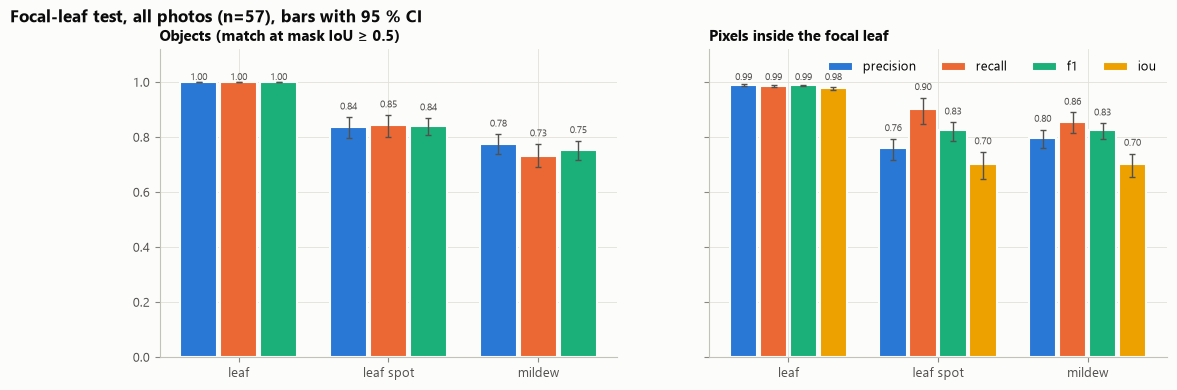

In [7]:
def bars(ax, x, vals, width, color, label=None, texts=True):
    y = np.array([v["value"] for v in vals])
    lo, hi = y - np.array([v["ci95"][0] for v in vals]), np.array([v["ci95"][1] for v in vals]) - y
    ax.bar(x, y, width, yerr=[np.maximum(lo, 0), np.maximum(hi, 0)], color=color, edgecolor=SURFACE, linewidth=1.5,
           error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 2}, label=label)
    if texts:
        for xi, yi, h_ in zip(x, y, hi):
            ax.text(xi, min(yi + h_ + 0.02, 1.0), f"{yi:.2f}", ha="center", va="bottom", fontsize=7.5, color=INK2)


fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, level, metrics in ((axes[0], "instance", ("precision", "recall", "f1")), (axes[1], "pixel", ("precision", "recall", "f1", "iou"))):
    x = np.arange(3); wbar = 0.8 / len(metrics)
    for j, m in enumerate(metrics):
        bars(ax, x + (j - (len(metrics) - 1) / 2) * wbar, [RESULTS["all"][f"{level}.{c}.{m}"] for c in CLASSES[1:]], wbar * 0.92, METRIC_COLOR[m], m)
    ax.set_xticks(x, [NICE[c] for c in CLASSES[1:]]); ax.set_ylim(0, 1.12)
    ax.set_title("Objects (match at mask IoU ≥ 0.5)" if level == "instance" else "Pixels inside the focal leaf")
axes[1].legend(loc="upper right", ncols=4, bbox_to_anchor=(1.0, 1.0))
fig.suptitle(f"Focal-leaf test, all photos (n={len(per_image)}), bars with 95 % CI", x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.savefig(OUT / "fig1_headline.png"); plt.show()

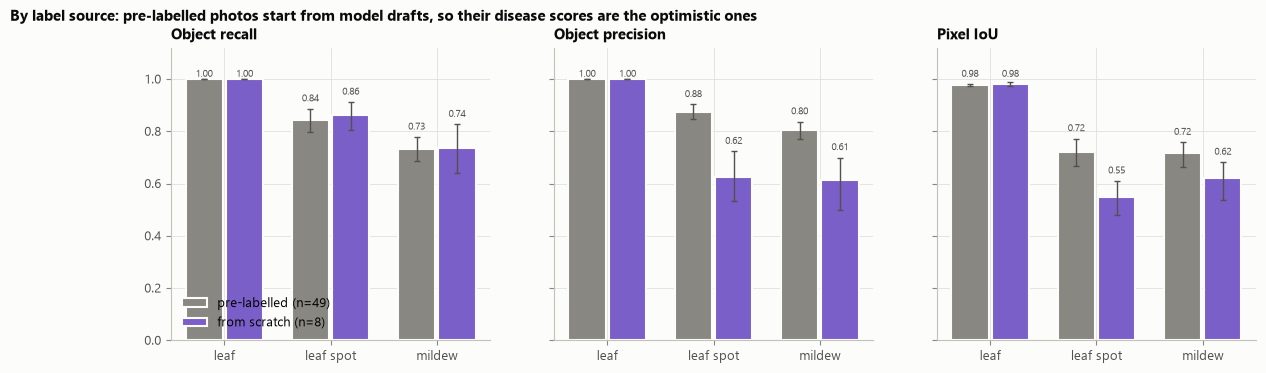

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
panels = [("Object recall", "instance.{c}.recall"), ("Object precision", "instance.{c}.precision"), ("Pixel IoU", "pixel.{c}.iou")]
for ax, (title, key) in zip(axes, panels):
    x = np.arange(3)
    for j, s in enumerate(SOURCES):
        bars(ax, x + (j - 0.5) * 0.38, [RESULTS[s["key"]][key.format(c=c)] for c in CLASSES[1:]], 0.35, SRC_COLOR[s["key"]],
             SRC_LABEL[s["key"]] if ax is axes[0] else None)
    ax.set_xticks(x, [NICE[c] for c in CLASSES[1:]]); ax.set_ylim(0, 1.12); ax.set_title(title)
axes[0].legend(loc="lower left")
fig.suptitle("By label source: pre-labelled photos start from model drafts, so their disease scores are the optimistic ones", x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
fig.savefig(OUT / "fig2_by_source.png"); plt.show()

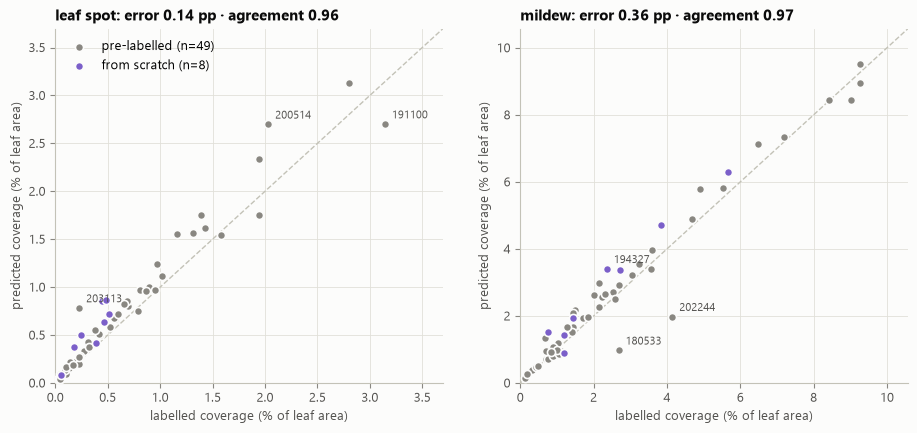

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, d in zip(axes, DISEASES):
    top = max(max(p["cov_gt"][d], p["cov_pred"][d]) for p in per_image) * 1.08 + 0.3
    ax.plot([0, top], [0, top], color=AXIS, linewidth=1, linestyle="--", zorder=1)
    for s in SOURCES:
        rows = GROUPS[s["key"]]
        ax.scatter([r["cov_gt"][d] for r in rows], [r["cov_pred"][d] for r in rows], s=34, color=SRC_COLOR[s["key"]], edgecolor=SURFACE,
                   linewidth=1.2, zorder=3, label=SRC_LABEL[s["key"]])
    worst = sorted(per_image, key=lambda r: -abs(r["cov_pred"][d] - r["cov_gt"][d]))[:3]
    for r in worst:
        ax.annotate(r["stem"][9:15], (r["cov_gt"][d], r["cov_pred"][d]), textcoords="offset points", xytext=(5, 4), fontsize=8, color=INK2)
    ax.set_xlim(0, top); ax.set_ylim(0, top)
    ax.set_xlabel("labelled coverage (% of leaf area)"); ax.set_ylabel("predicted coverage (% of leaf area)")
    ax.set_title(f"{NICE[d]}: error {RESULTS['all'][f'coverage.{d}.mae']['value']:.2f} pp · agreement {RESULTS['all'][f'coverage.{d}.ccc']['value']:.2f}")
axes[0].legend(loc="upper left")
fig.savefig(OUT / "fig3_coverage_scatter.png"); plt.show()

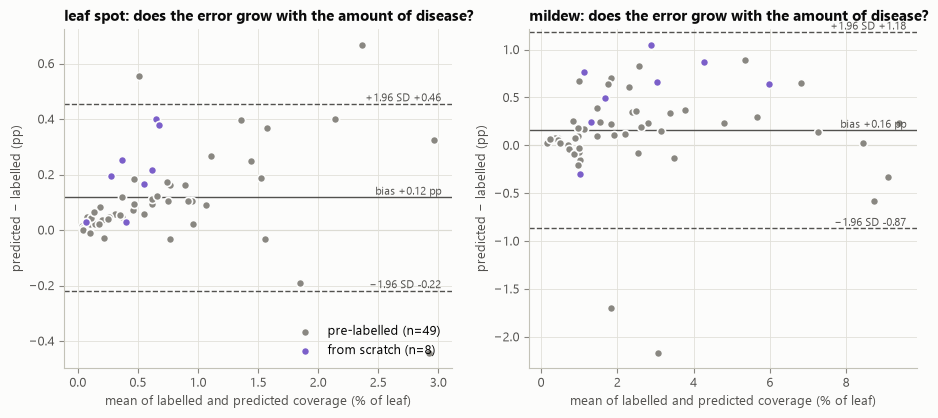

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, d in zip(axes, DISEASES):
    g = np.array([r["cov_gt"][d] for r in per_image]); p = np.array([r["cov_pred"][d] for r in per_image])
    mean, diff = (g + p) / 2, p - g
    bias, sd = diff.mean(), diff.std(ddof=1)
    for s in SOURCES:
        idx = [i for i, r in enumerate(per_image) if r["source"] == s["key"]]
        ax.scatter(mean[idx], diff[idx], s=34, color=SRC_COLOR[s["key"]], edgecolor=SURFACE, linewidth=1.2, zorder=3, label=SRC_LABEL[s["key"]])
    for y, lab, ls in ((bias, f"bias {bias:+.2f} pp", "-"), (bias + 1.96 * sd, f"+1.96 SD {bias + 1.96 * sd:+.2f}", "--"), (bias - 1.96 * sd, f"−1.96 SD {bias - 1.96 * sd:+.2f}", "--")):
        ax.axhline(y, color=INK2, linewidth=1, linestyle=ls, zorder=1)
        ax.text(ax.get_xlim()[1] if False else mean.max() * 1.02, y, lab, va="bottom", ha="right", fontsize=8, color=INK2)
    ax.axhline(0, color=AXIS, linewidth=0.8, zorder=0)
    ax.set_xlabel("mean of labelled and predicted coverage (% of leaf)"); ax.set_ylabel("predicted − labelled (pp)")
    ax.set_title(f"{NICE[d]}: does the error grow with the amount of disease?")
axes[0].legend(loc="lower right")
fig.savefig(OUT / "fig4_bland_altman.png"); plt.show()

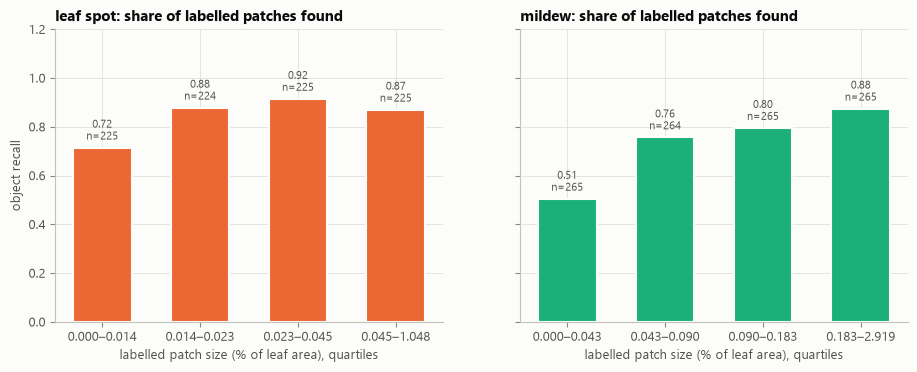

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, d in zip(axes, DISEASES):
    area = np.array([a for p in per_image for a in p["gt_area_frac"][d]])
    hit = np.array([h for p in per_image for h in p["gt_hit"][d]])
    edges = np.quantile(area, [0, 0.25, 0.5, 0.75, 1.0]); edges[-1] += 1e-9
    b = np.digitize(area, edges[1:-1])
    rec = [hit[b == i].mean() for i in range(4)]; n = [int((b == i).sum()) for i in range(4)]
    x = np.arange(4)
    ax.bar(x, rec, 0.6, color=CLASS_COLOR[d], edgecolor=SURFACE, linewidth=1.5)
    for xi, r_, n_ in zip(x, rec, n):
        ax.text(xi, r_ + 0.02, f"{r_:.2f}\nn={n_}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_xticks(x, [f"{edges[i]:.3f}–{edges[i + 1]:.3f}" for i in range(4)])
    ax.set_ylim(0, 1.2); ax.set_xlabel("labelled patch size (% of leaf area), quartiles"); ax.set_title(f"{NICE[d]}: share of labelled patches found")
axes[0].set_ylabel("object recall")
fig.savefig(OUT / "fig5_recall_by_size.png"); plt.show()

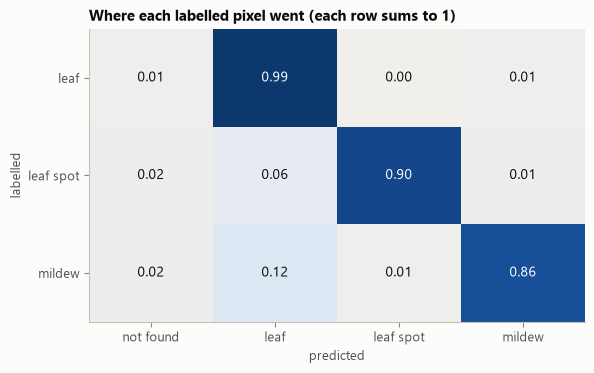

Severity band, labelled (rows) vs predicted (columns), photos:

leaf_spot
                  none      mild  moderate    severe
mild                 0        57         0         0

powdery_mildew
                  none      mild  moderate    severe
mild                 0        48         1         0
moderate             0         0         8         0


In [12]:
cm = np.zeros((3, 4), np.int64)  # labelled class (leaf, spot, mildew) x predicted (not found, leaf, spot, mildew), pixels inside the focal leaf
for p in per_image:
    gt_map, pred_map, leaf_gt = p["maps"]
    cm += np.bincount((gt_map[leaf_gt].astype(np.int64) - 1) * 4 + pred_map[leaf_gt], minlength=12).reshape(3, 4)
cn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.imshow(cn, cmap=BLUES, vmin=0, vmax=1, aspect="auto"); ax.grid(False)
for i in range(3):
    for j in range(4):
        ax.text(j, i, f"{cn[i, j]:.2f}", ha="center", va="center", color="white" if cn[i, j] > 0.55 else INK, fontsize=10)
ax.set_xticks(range(4), ["not found", "leaf", "leaf spot", "mildew"]); ax.set_yticks(range(3), ["leaf", "leaf spot", "mildew"])
ax.set_xlabel("predicted"); ax.set_ylabel("labelled"); ax.set_title("Where each labelled pixel went (each row sums to 1)")
fig.savefig(OUT / "fig6_pixel_confusion.png"); plt.show()

print("Severity band, labelled (rows) vs predicted (columns), photos:")
for d in DISEASES:
    c = collections.Counter((sev(r["cov_gt"][d]), sev(r["cov_pred"][d])) for r in per_image)
    bands = ["none", "mild", "moderate", "severe"]
    print(f"\n{d}\n{'':<12}" + "".join(f"{b:>10}" for b in bands))
    for a in bands:
        if any(c[(a, b)] for b in bands):
            print(f"{a:<12}" + "".join(f"{c[(a, b)]:>10}" for b in bands))

## 5 · Ultralytics `val`

Every photo is greyed out except the labelled focal leaf (2-px edge, no margin), so neighbouring leaves cannot produce unlabelled predictions. The labels are unchanged. This is the standard Ultralytics table with its own plots; its precision and recall are read at one confidence for all classes, not at the app's thresholds.

In [13]:
iso = OUT / "focal_only_yolo"
shutil.rmtree(iso, ignore_errors=True)
(iso / "images").mkdir(parents=True); (iso / "labels").mkdir()
kernel = np.ones((5, 5), np.uint8)
n_img = 0
for p in per_image:
    lbl = DS[p["source"]]["yolo_dir"] / "test" / "labels" / (Path(p["file"]).stem + ".txt")
    if not lbl.exists():
        print("no label file, skipped:", p["file"]); continue
    keep = cv2.dilate(p["maps"][2].astype(np.uint8), kernel).astype(bool)
    Image.fromarray(np.where(keep[..., None], np.asarray(p["im"]), np.array(GREY, np.uint8))).save(iso / "images" / p["file"], quality=95)
    shutil.copy(lbl, iso / "labels"); n_img += 1
yolo = YOLO(CHECKPOINT)
for s in SOURCES:
    assert list(yaml.safe_load(open(DS[s["key"]]["yaml"]))["names"]) == list(yolo.names.values()), f"class order differs in {s['key']}"
yaml.safe_dump({"path": str(iso), "train": "images", "val": "images", "names": list(yolo.names.values())}, open(OUT / "focal_only.yaml", "w"))
val = yolo.val(data=str(OUT / "focal_only.yaml"), imgsz=APP_IMGSZ, batch=4, conf=0.001, iou=0.7, workers=0, plots=True,
               project=str(OUT), name="ultralytics_combined", exist_ok=True, verbose=False)
UL = {}
print(f"\nUltralytics val · {n_img} photos · neighbouring leaves greyed out\n")
print(f"{'':<16}{'mask P':>9}{'mask R':>9}{'mAP50':>9}{'mAP50-95':>10}{'box P':>9}{'box R':>9}{'mAP50':>9}{'mAP50-95':>10}")
names = yolo.names
rows_ul = [("all", val.seg.mp, val.seg.mr, val.seg.map50, val.seg.map, val.box.mp, val.box.mr, val.box.map50, val.box.map)]
for i, ci in enumerate(val.seg.ap_class_index):
    rows_ul.append((names[int(ci)], *val.seg.class_result(i), *val.box.class_result(i)))
for r in rows_ul:
    UL[r[0]] = {"mask": {"p": float(r[1]), "r": float(r[2]), "map50": float(r[3]), "map50_95": float(r[4])},
                "box": {"p": float(r[5]), "r": float(r[6]), "map50": float(r[7]), "map50_95": float(r[8])}}
    print(f"{r[0]:<16}" + "".join(f"{float(v):>9.3f}" if k not in (3, 7) else f"{float(v):>10.3f}" for k, v in enumerate(r[1:])))

Ultralytics 8.4.184  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 5000 Blackwell, 48935MiB)
YOLO26x-seg summary (fused): 204 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 602.4±166.8 MB/s, size: 387.4 KB)
val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_test_combined\focal_only_yolo\labels... 57 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 57/57 1.1Kit/s 0.1s
val: New cache created: C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_test_combined\focal_only_yolo\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.7it/s 3.2s0.2s
                   all         57       2016      0.837       0.84       0.88      0.656      0.793      0.765      0.794      0.556
Speed: 0.4ms preprocess, 16.5ms inference, 0.0ms loss, 2.9ms postprocess per imag

MaskPR_curve.png


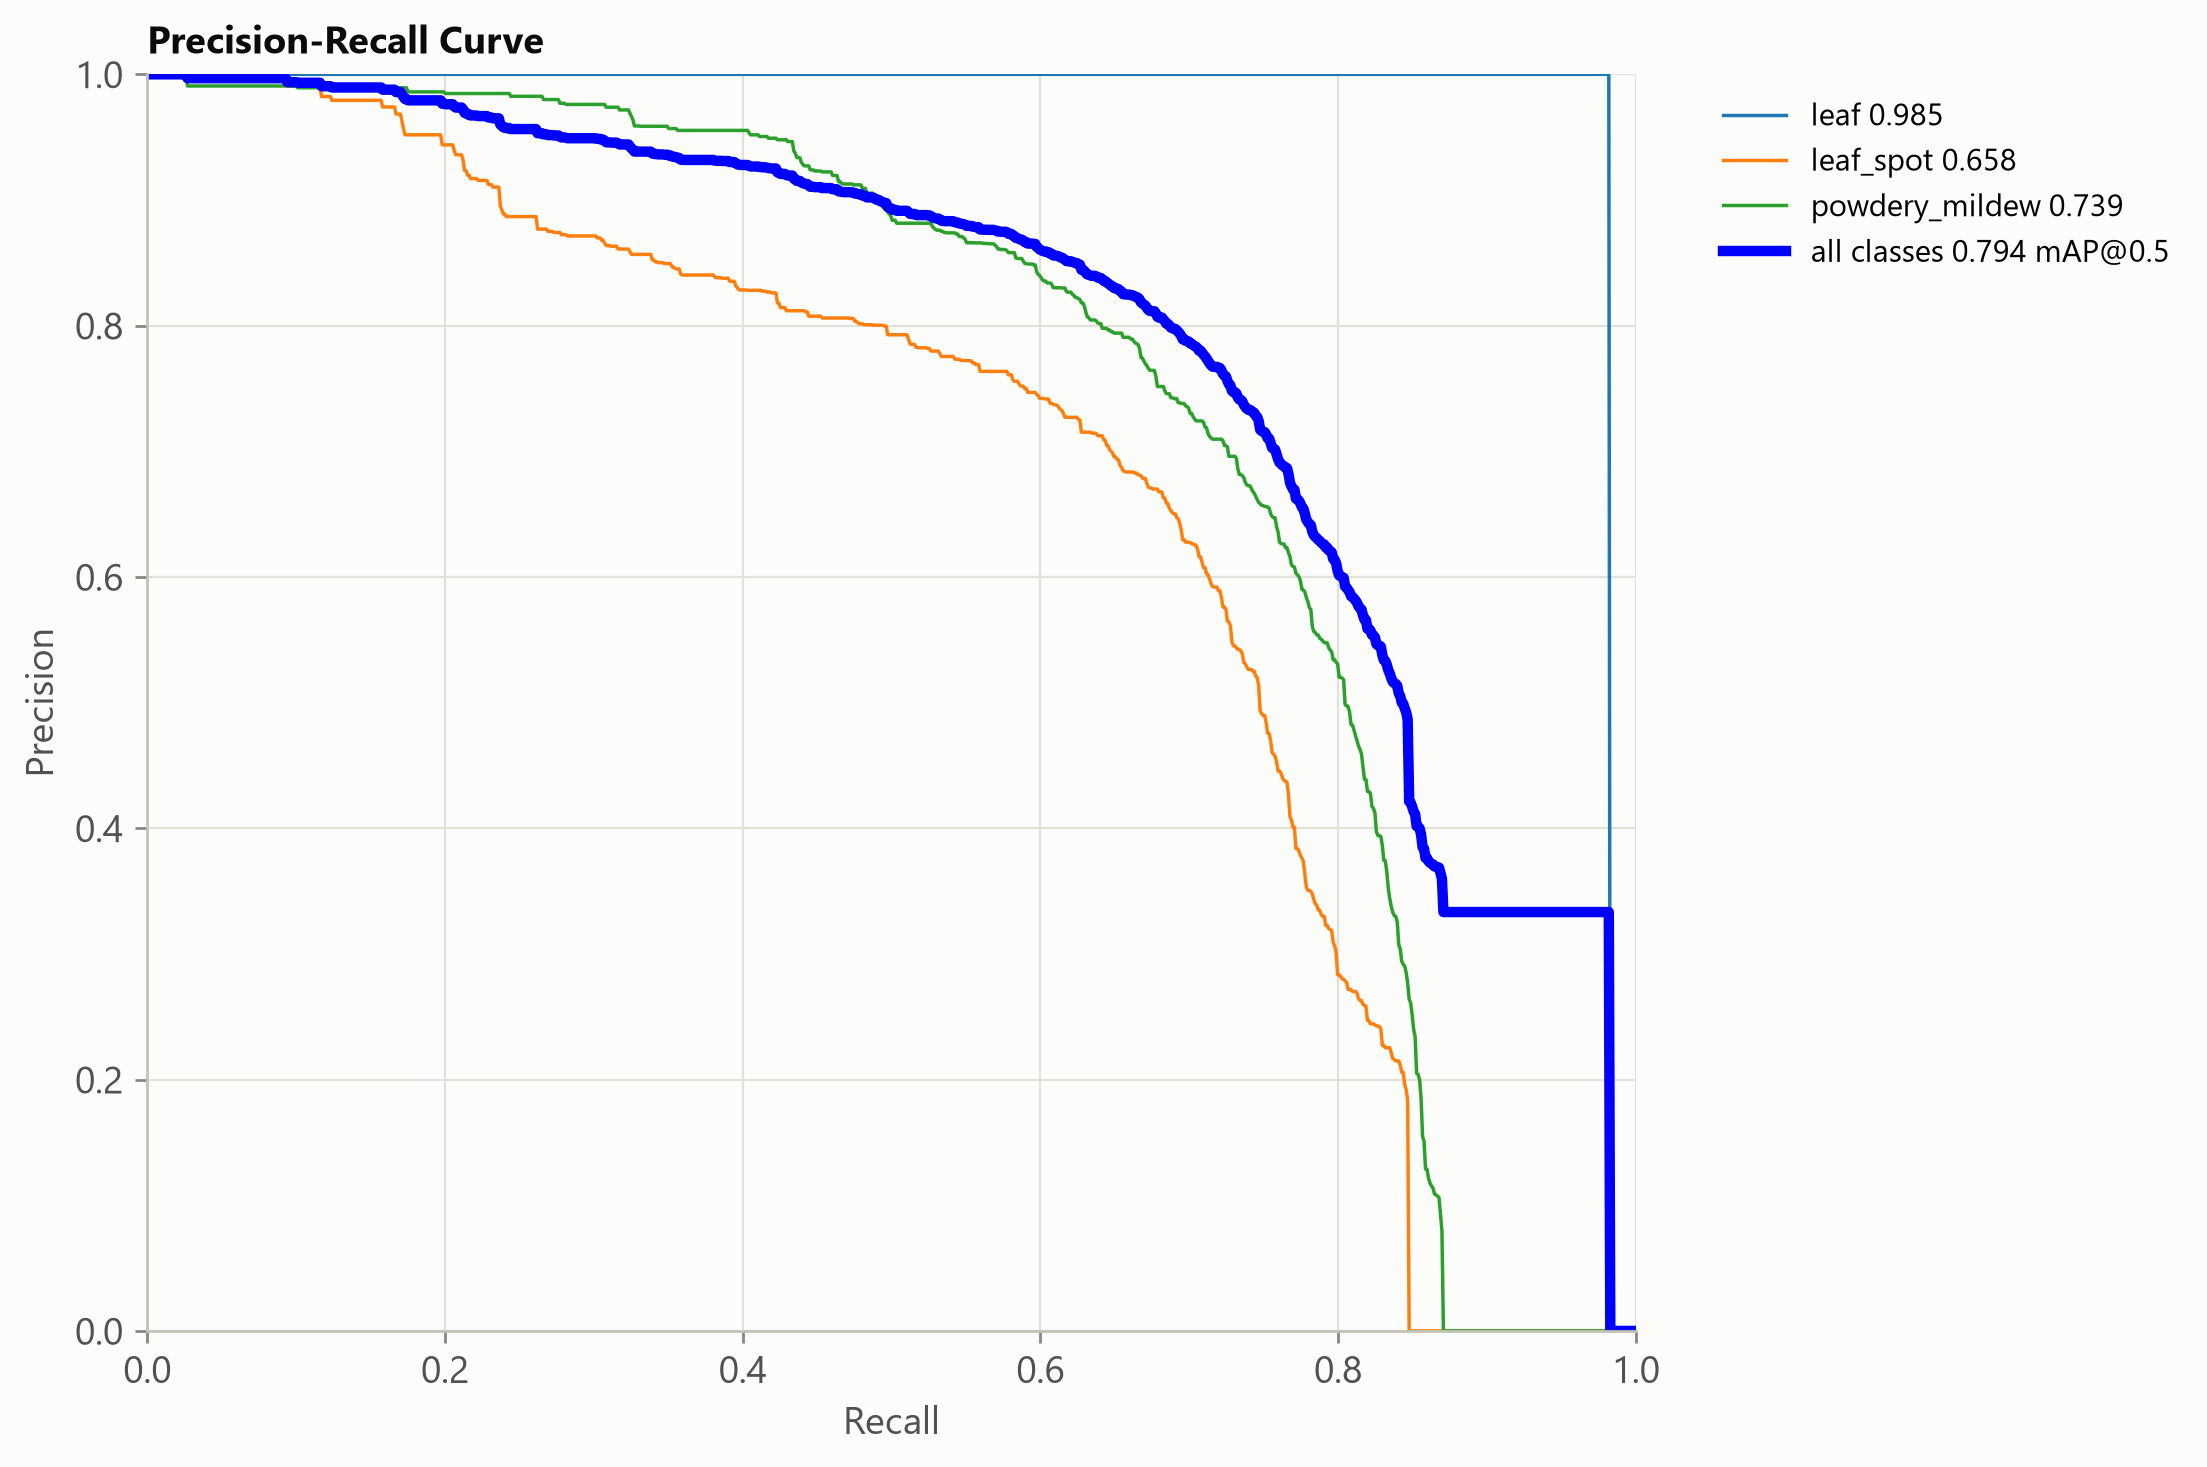

MaskF1_curve.png


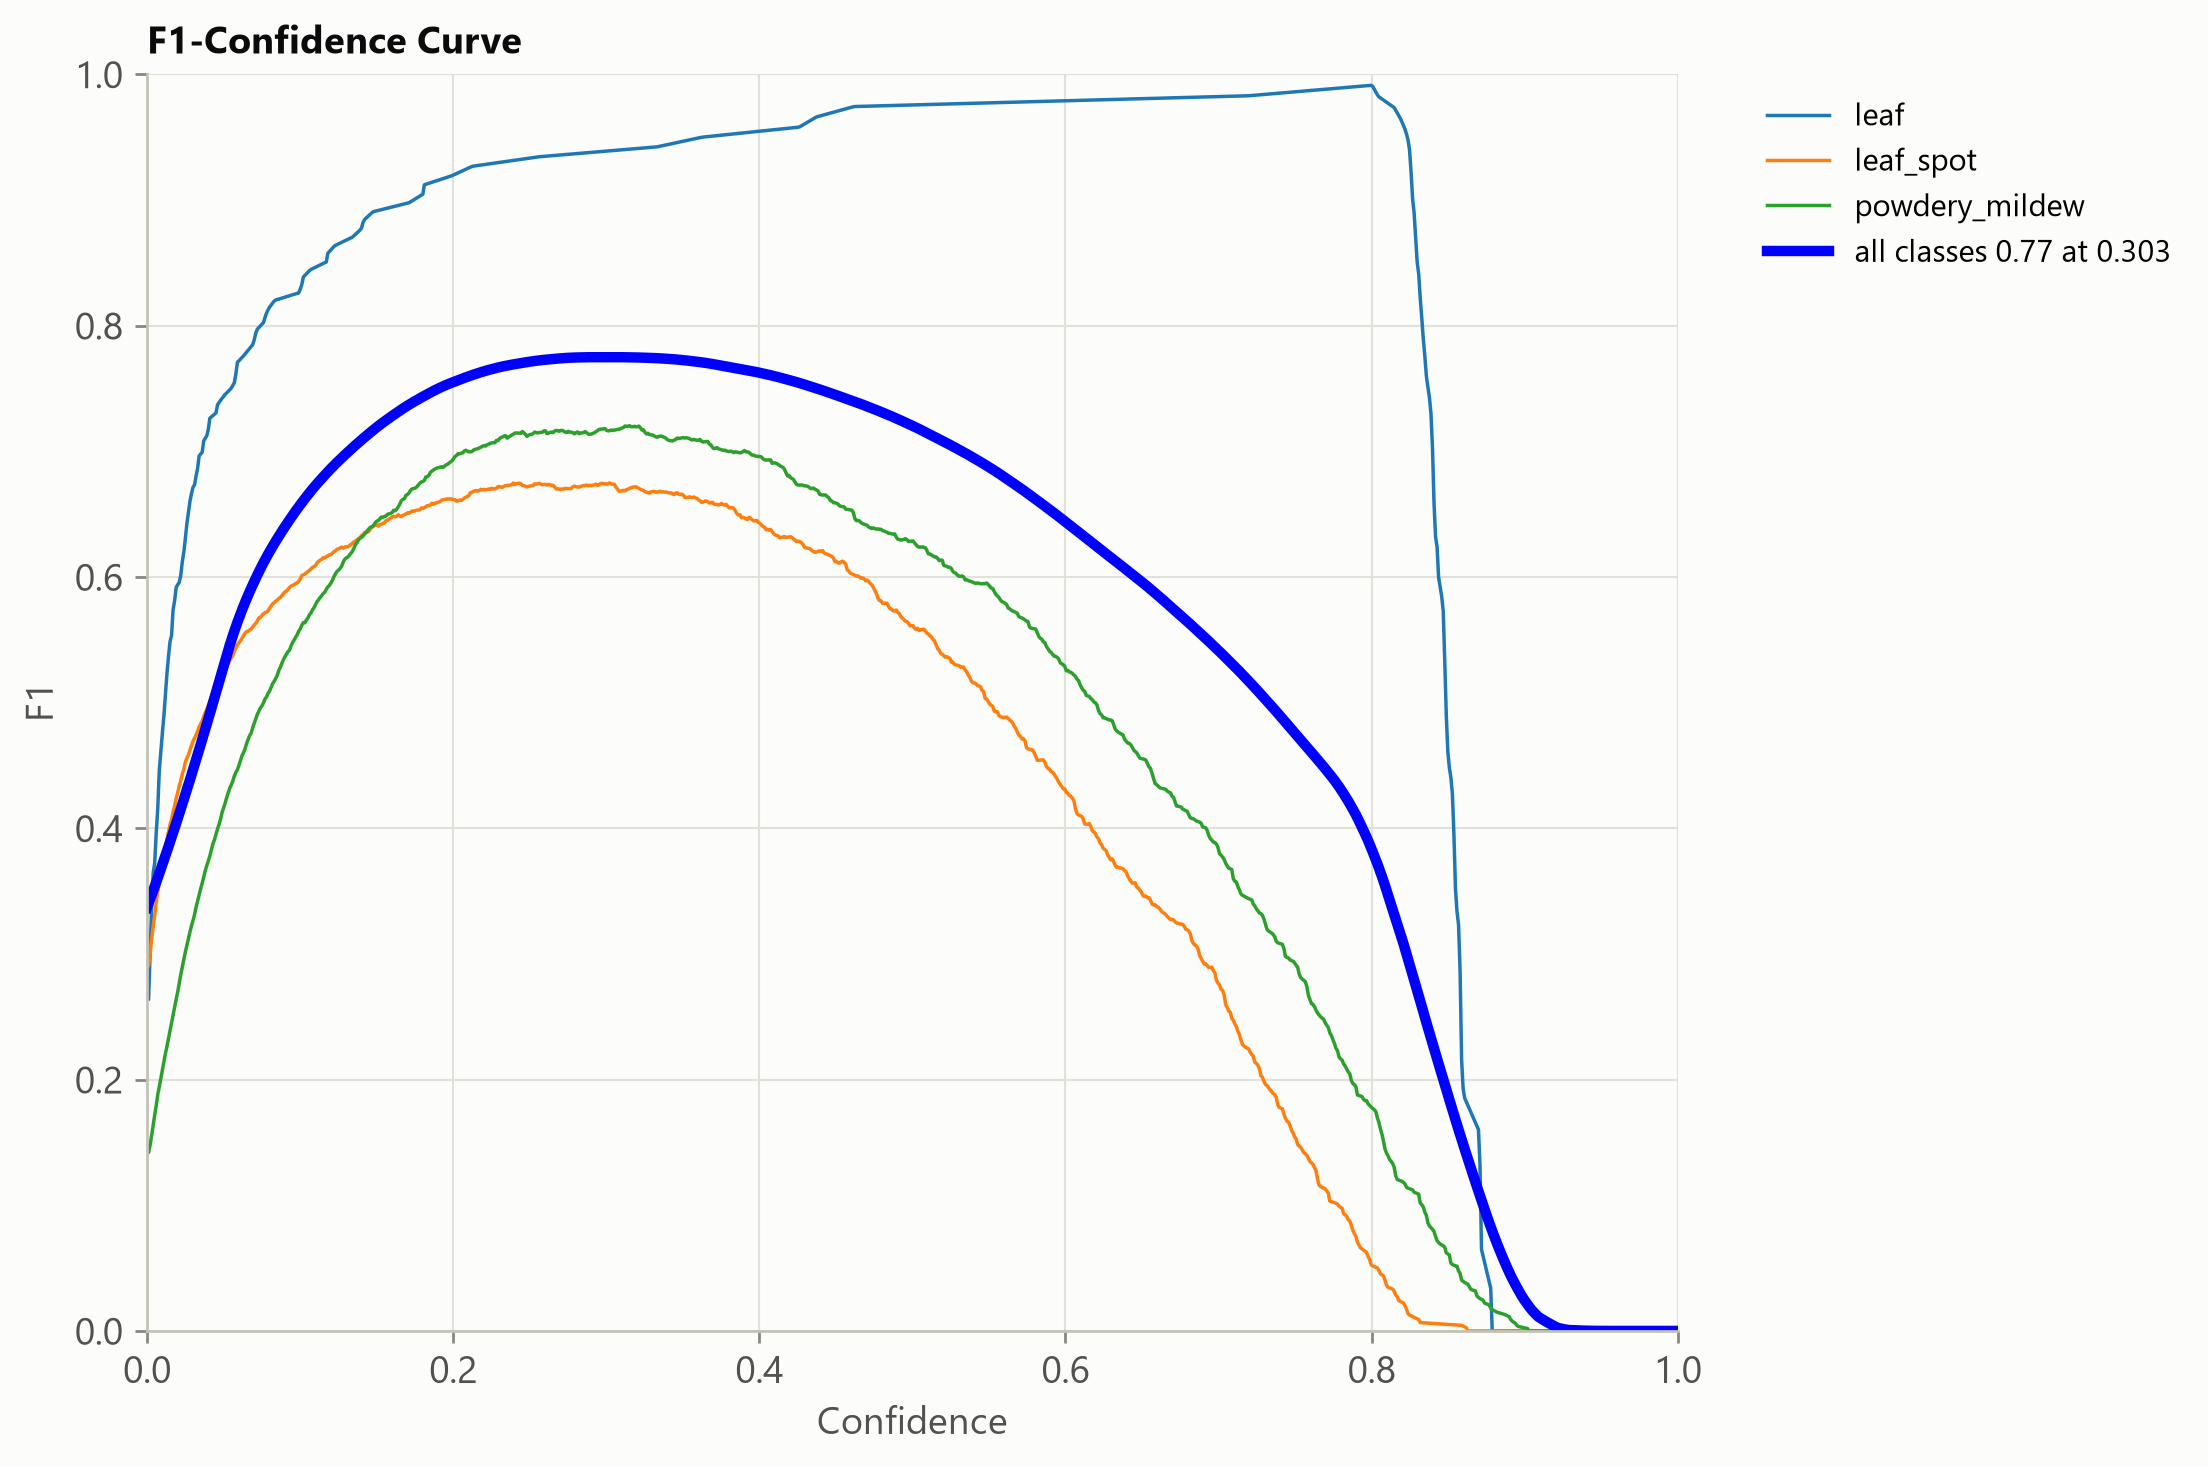

confusion_matrix_normalized.png


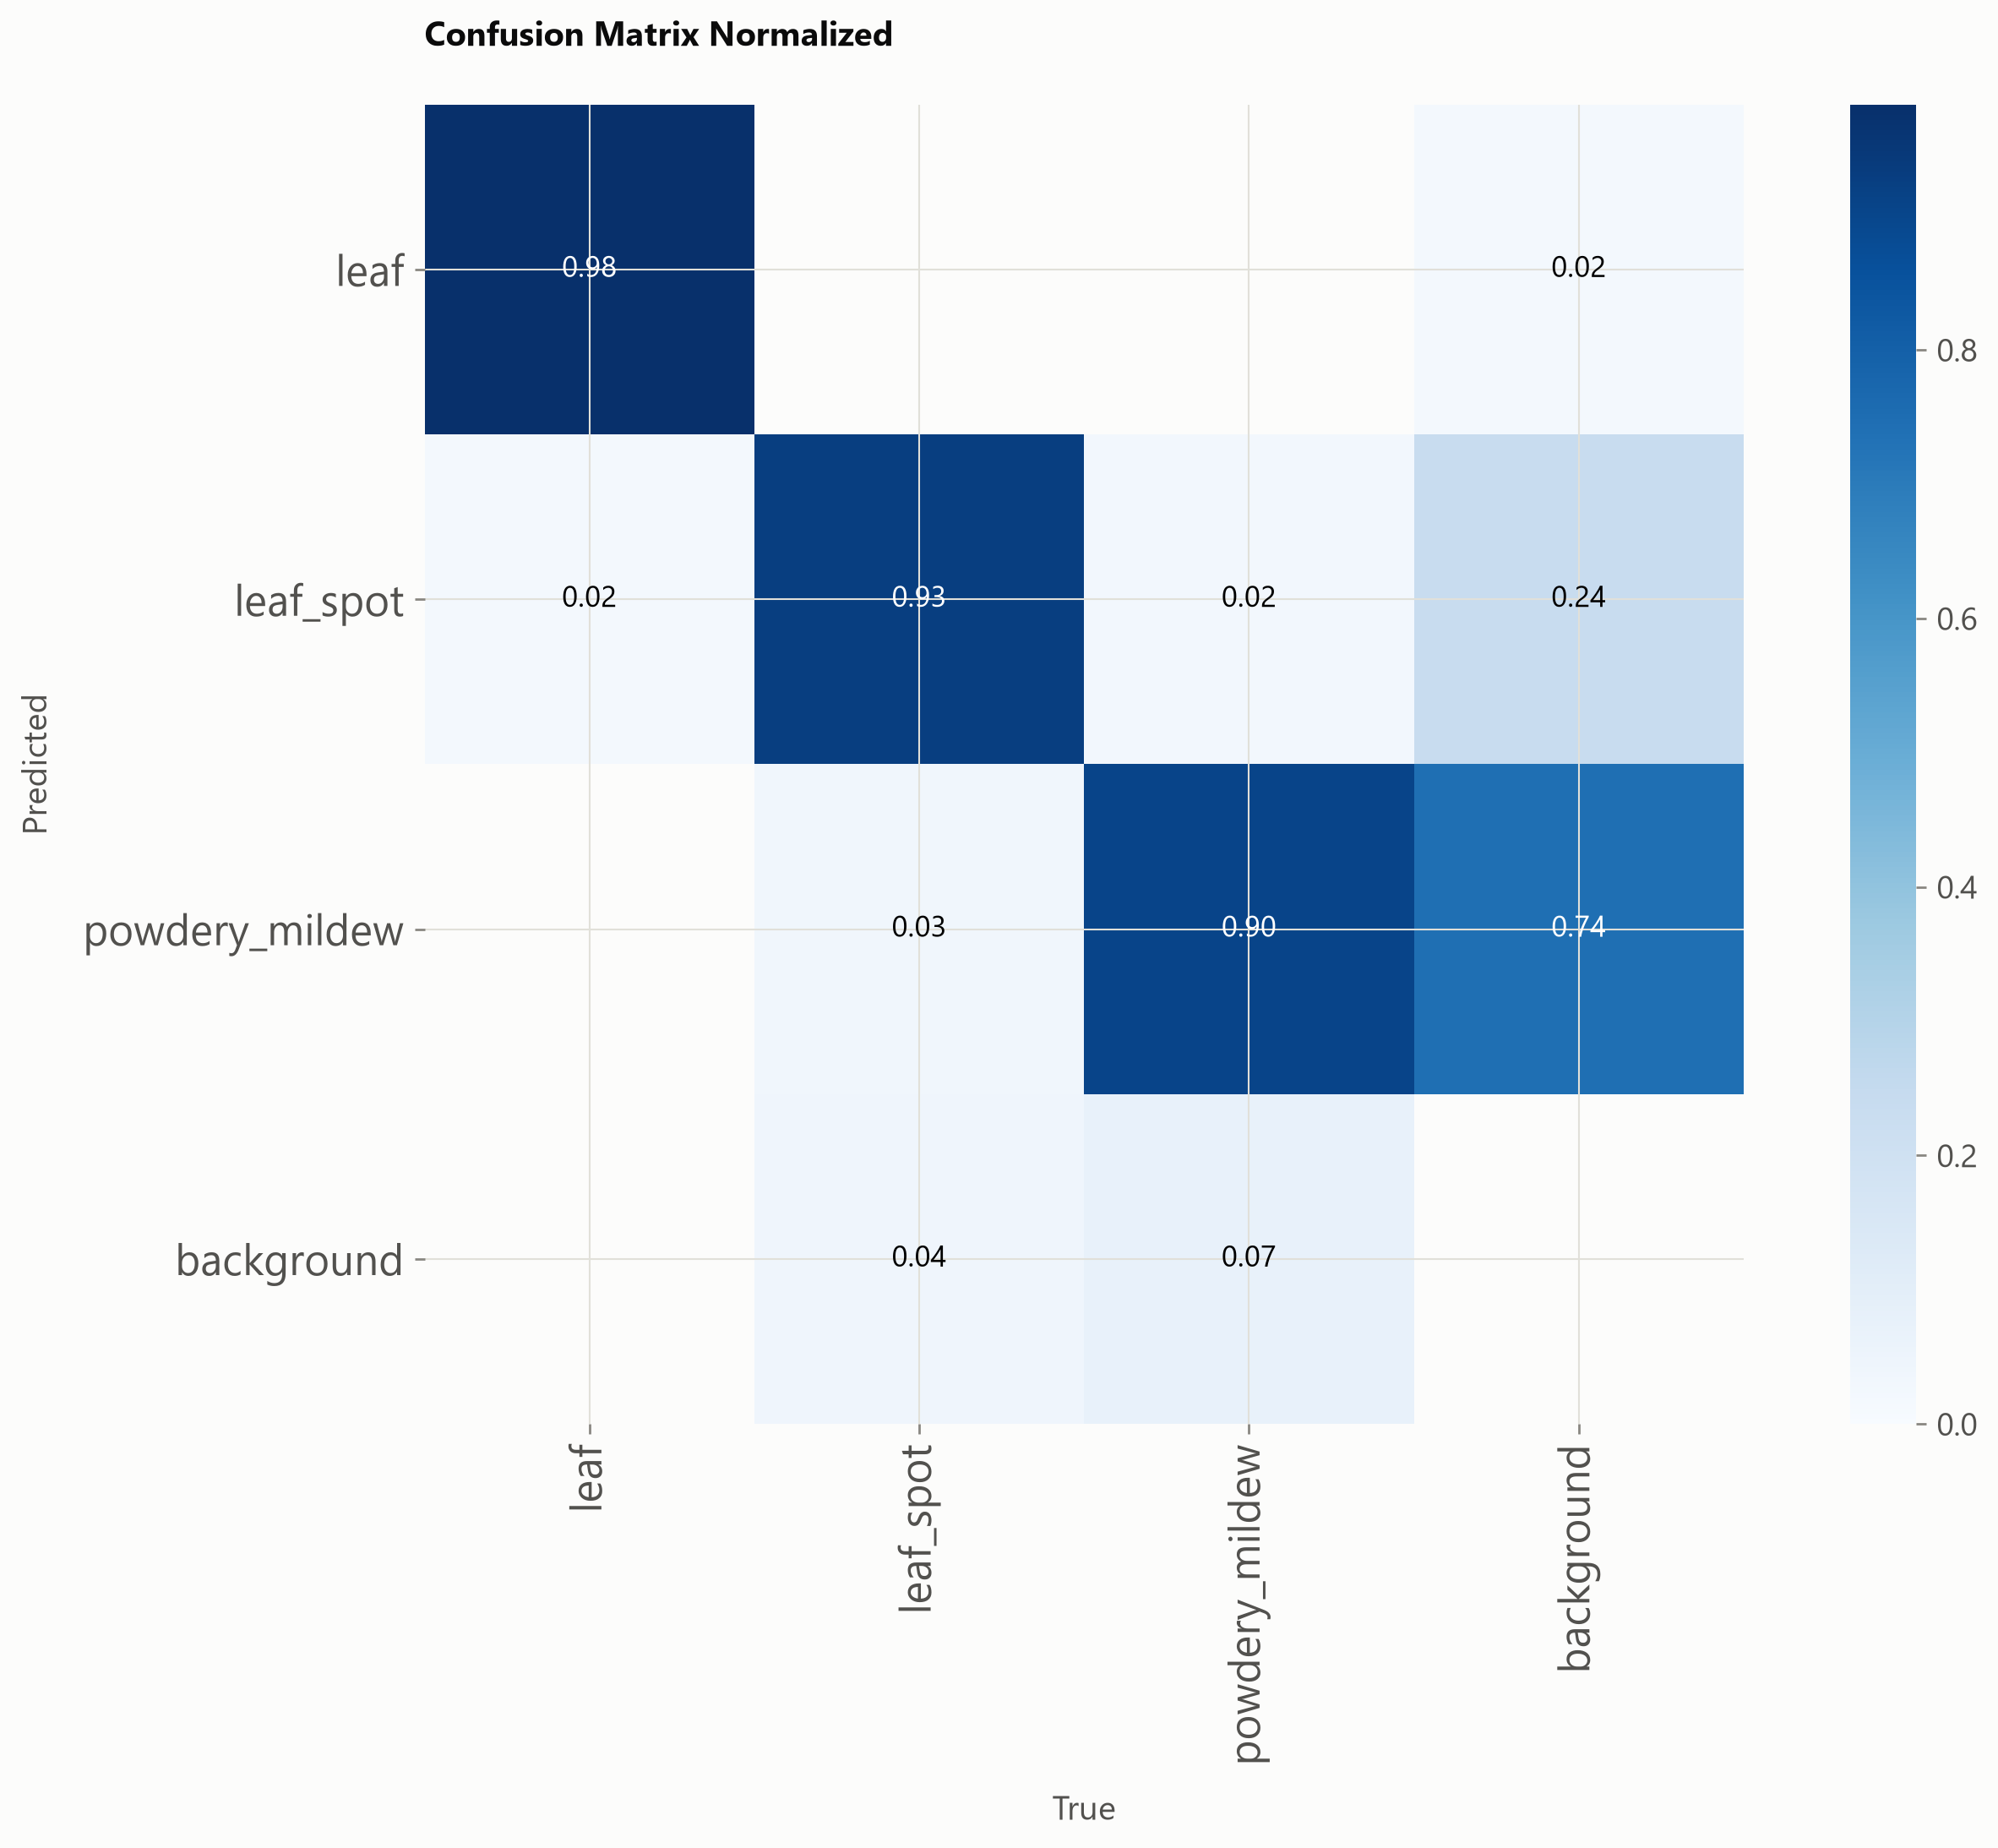

In [14]:
plots = OUT / "ultralytics_combined"
for f in ("MaskPR_curve.png", "MaskF1_curve.png", "confusion_matrix_normalized.png"):
    path = plots / f
    if path.exists():
        print(f); display(IPImage(filename=str(path), width=720))

## 6 · Per photo

In [15]:
print(f"{'photo':<8}{'source':<13}{'leaf IoU':>9}{'spot % lab→pred':>18}{'spot TP/FP/FN':>15}{'mildew % lab→pred':>20}{'mildew TP/FP/FN':>17}")
rows_csv = []
for p in sorted(per_image, key=lambda r: r["stem"]):
    s, m = p["inst"]["leaf_spot"], p["inst"]["powdery_mildew"]
    print(f"{p['stem'][9:15]:<8}{p['source']:<13}{p['leaf_iou']:>9.2f}{p['cov_gt']['leaf_spot']:>9.2f} → {p['cov_pred']['leaf_spot']:<6.2f}{'/'.join(map(str, s)):>15}"
          f"{p['cov_gt']['powdery_mildew']:>10.2f} → {p['cov_pred']['powdery_mildew']:<7.2f}{'/'.join(map(str, m)):>17}")
    rows_csv.append({"photo": p["stem"], "source": p["source"], "leaf_iou": round(p["leaf_iou"], 4),
                     **{f"labelled_{d}_pct": round(p["cov_gt"][d], 3) for d in DISEASES},
                     **{f"predicted_{d}_pct": round(p["cov_pred"][d], 3) for d in DISEASES},
                     "spot_tp_fp_fn": "/".join(map(str, s)), "mildew_tp_fp_fn": "/".join(map(str, m)),
                     "neighbour_leaves_ignored": p["other_leaves_ignored"]})

photo   source        leaf IoU   spot % lab→pred  spot TP/FP/FN   mildew % lab→pred  mildew TP/FP/FN
175815  prelabelled       0.92     0.70 → 0.80           15/3/1      9.27 → 8.94             29/9/20
175855  prelabelled       0.97     0.35 → 0.39           16/2/9      4.91 → 5.80            42/18/26
175923  prelabelled       0.96     1.32 → 1.57          29/9/10      9.27 → 9.51              35/9/9
175957  prelabelled       0.94     0.97 → 1.24           41/7/3      2.69 → 2.93              20/5/5
180051  prelabelled       0.97     1.94 → 1.75           20/4/8      1.43 → 1.68              11/1/5
180435  prelabelled       0.98     0.13 → 0.15            4/0/0      2.53 → 2.72              11/2/5
180533  prelabelled       0.98     1.39 → 1.75           43/4/1      2.68 → 0.98              4/1/14
180558  prelabelled       0.97     0.42 → 0.50           14/4/5      5.52 → 5.83              29/1/7
181552  scratch           0.98     0.39 → 0.42           10/5/2      1.18 → 0.88           

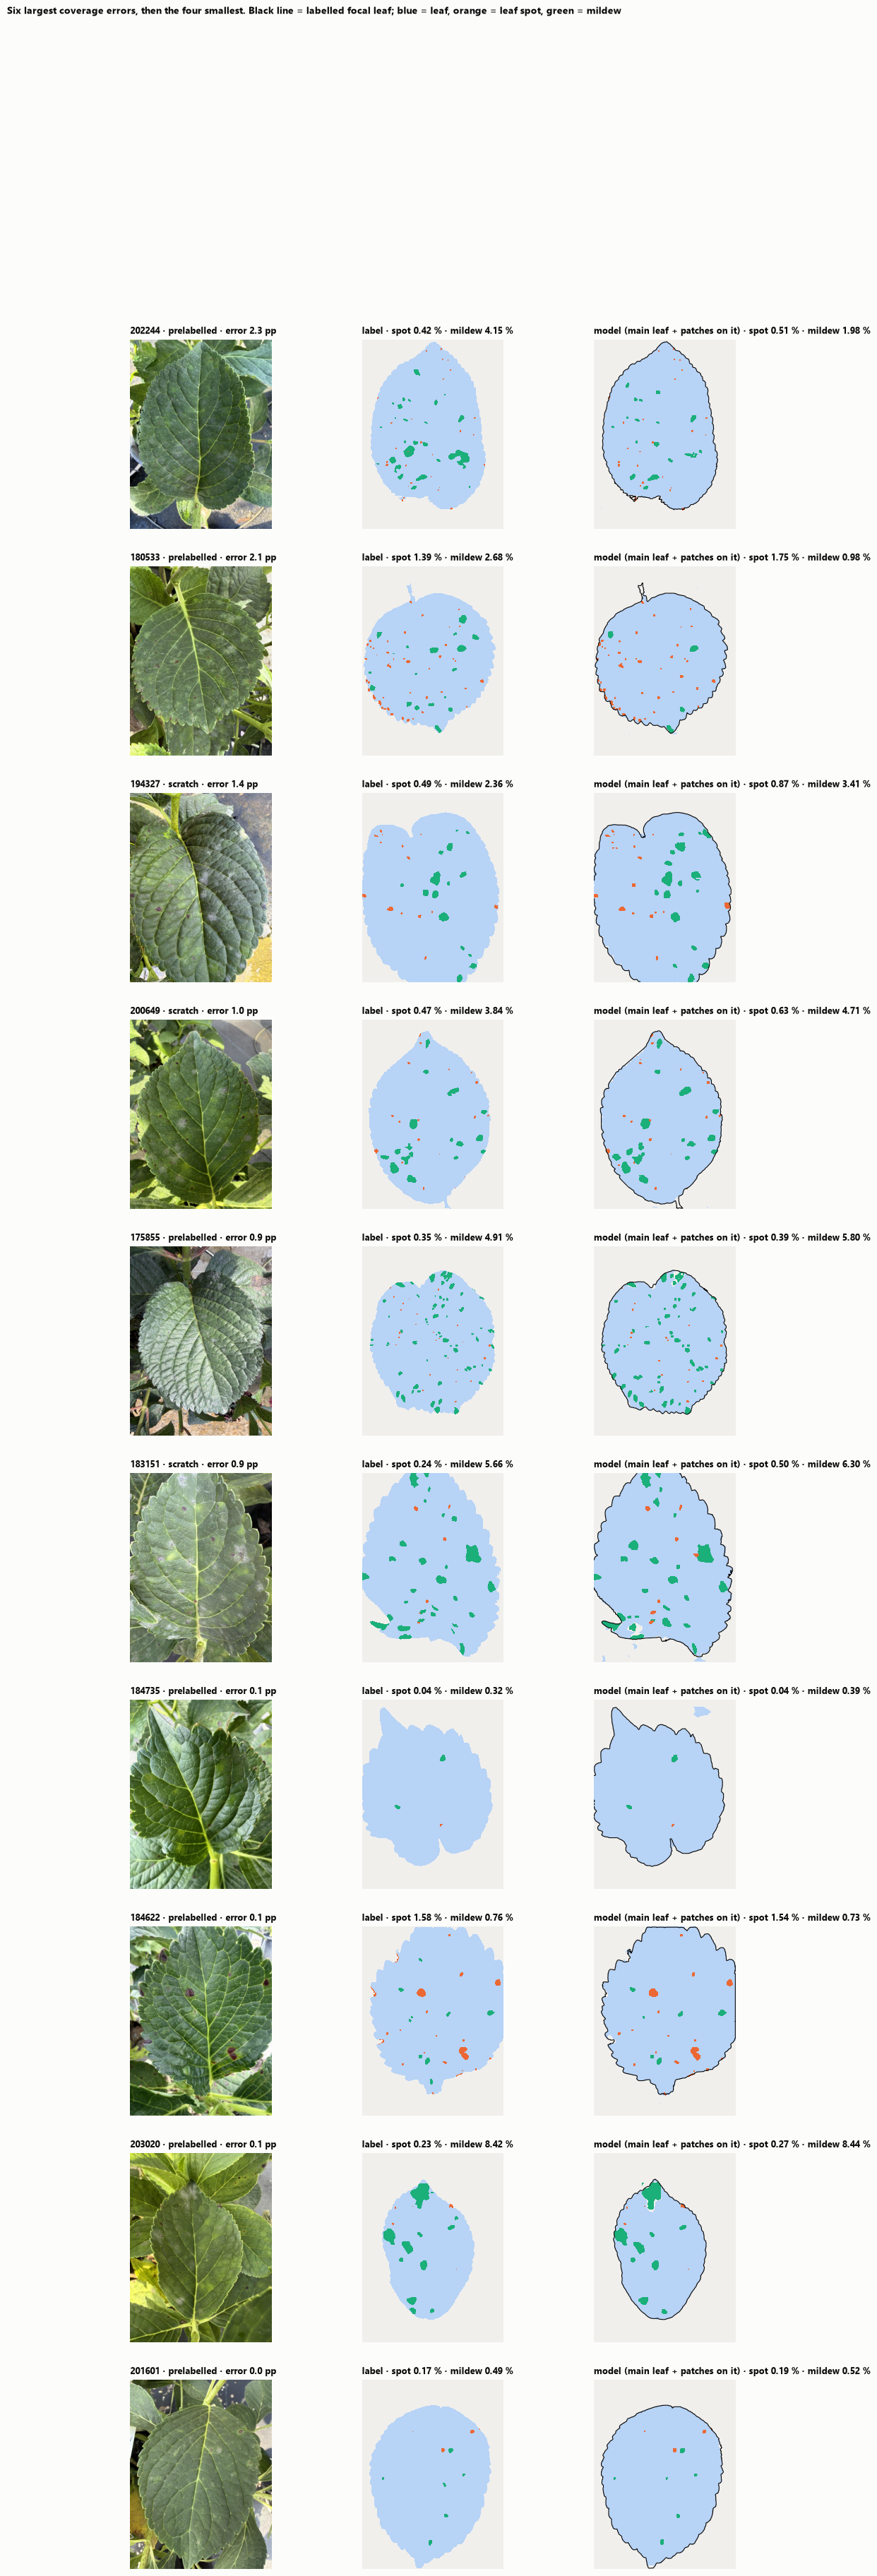

In [16]:
err = {p["id"]: abs(p["cov_pred"]["leaf_spot"] - p["cov_gt"]["leaf_spot"]) + abs(p["cov_pred"]["powdery_mildew"] - p["cov_gt"]["powdery_mildew"]) for p in per_image}
order = sorted(per_image, key=lambda p: -err[p["id"]])
show = order[:6] + order[-4:]  # six largest coverage errors, four smallest
fig, axes = plt.subplots(len(show), 3, figsize=(12, 4.1 * len(show)))
for axr, p in zip(axes, show):
    gt_map, pred_map, leaf_gt = p["maps"]
    axr[0].imshow(p["im"]); axr[0].set_title(f"{p['stem'][9:15]} · {p['source']} · error {err[p['id']]:.1f} pp", fontsize=9)
    axr[1].imshow(np.where(leaf_gt, gt_map, 0), cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[1].set_title(f"label · spot {p['cov_gt']['leaf_spot']:.2f} % · mildew {p['cov_gt']['powdery_mildew']:.2f} %", fontsize=9)
    axr[2].imshow(pred_map, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[2].contour(leaf_gt, levels=[0.5], colors=[INK], linewidths=0.8)
    axr[2].set_title(f"model (main leaf + patches on it) · spot {p['cov_pred']['leaf_spot']:.2f} % · mildew {p['cov_pred']['powdery_mildew']:.2f} %", fontsize=9)
    for ax in axr:
        ax.axis("off")
fig.suptitle("Six largest coverage errors, then the four smallest. Black line = labelled focal leaf; blue = leaf, orange = leaf spot, green = mildew",
             x=0.01, y=0.995, ha="left", fontsize=10, fontweight="bold", color=INK)
fig.savefig(OUT / "fig7_examples.png", dpi=90); plt.show()

## 7 · Save

In [17]:
with open(OUT / "per_image.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows_csv[0])); w.writeheader(); w.writerows(rows_csv)
json.dump({"sources": {s["key"]: {"project": s["project"], "version": s["version"], "photos": n_src[s["key"]]} for s in SOURCES},
           "model": ONNX.name, "thresholds": THRESH, "match_iou": MATCH_IOU, "photos_scored": len(per_image),
           "metrics": RESULTS, "mask_ap": AP, "ultralytics_val": UL}, open(OUT / "metrics.json", "w"), indent=1)
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['fig1_headline.png', 'fig2_by_source.png', 'fig3_coverage_scatter.png', 'fig4_bland_altman.png', 'fig5_recall_by_size.png', 'fig6_pixel_confusion.png', 'fig7_examples.png', 'focal_only.yaml', 'focal_only_yolo', 'metrics.json', 'per_image.csv', 'ultralytics_combined']
